# PRIMs Tutorial — Unit 3: Operator Selection

*Notebook version for pyprims. Open it from the `Unit 3` folder. The batch run near the end takes about a minute.*

In [1]:
from pyprims.notebook import Session, Dashboard, figure, plot_batch, read_batch
from IPython.display import Image

def show_model(path):
    """Print a model file."""
    print(open(path, encoding="utf-8").read())

## Competition between operators

An operator is a chunk in declarative memory, so just like any other chunk it has a base-level activation and strengths of association with other chunks. As with any other chunk, these activations correspond to the odds that we need the operator in the current context. This means that the choice of operator is based on how much spreading activation it receives from the current context.

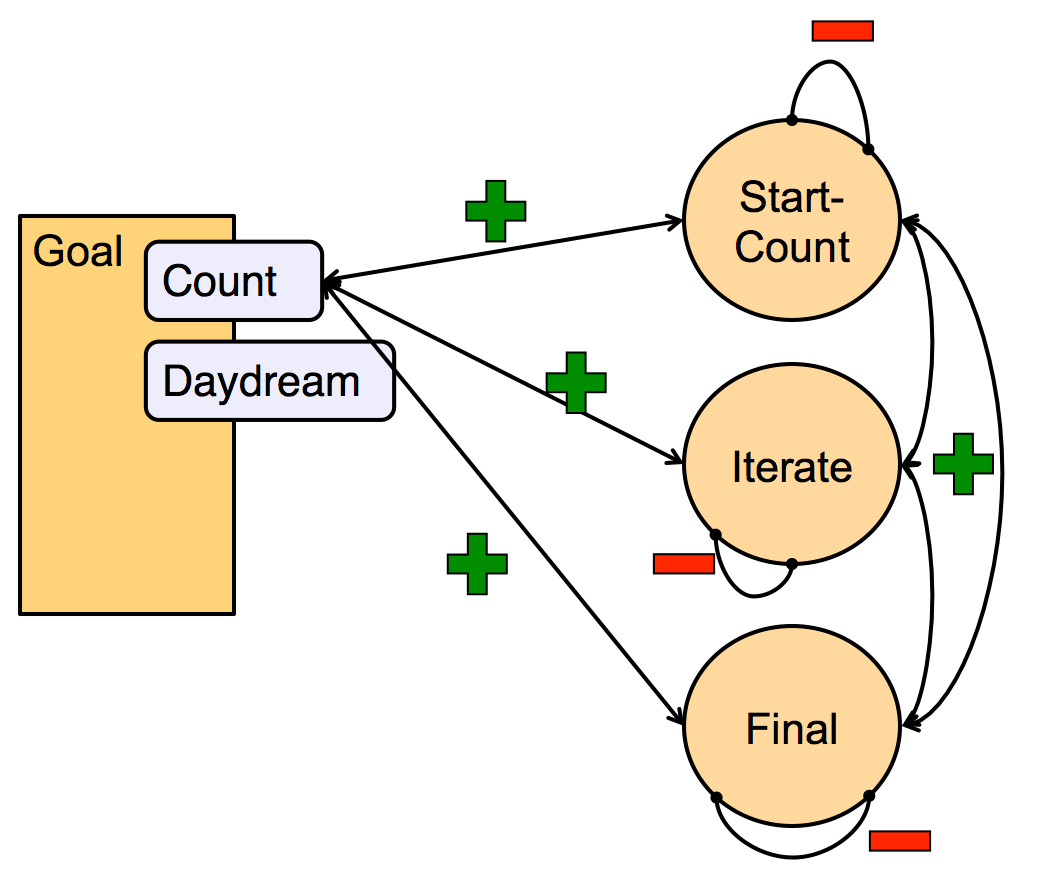

In [2]:
Image("figures/operator-associations.png", width=450)

The figure shows the key associations that determine the selection process. The first, and most important, is the association between a **skill and an operator**. If a skill is active, it favors the operators with which it is associated. The second is the association **between operators**, typically of the same skill. This promotes sticking to a particular skill instead of switching to another. The last is a **negative self-association**, which discourages using the same operator twice in a row.

In the models we have looked at so far, these associations were set automatically: all operators receive a positive association with the skill in which they are defined ($S_{ji}$ = `default-operator-assoc:`, default 3.0), all operators within a skill have a positive association with one another (`default-inter-operator-assoc:`, default 1.0), and all operators are negatively associated with themselves (`default-operator-self-assoc:`, default −1.0).

PRIMs does not necessarily execute operators that are linked to one of the active skills. If none of the operators linked to a skill have matching conditions, another operator may be chosen. Or another operator may be chosen if another source of spreading activation is stronger than the spreading activation from the goal. For example, strong perceptual input (someone calling your name) can activate operators to attend to that input.

## Learning new skills

Other operators also have to be chosen when we have to learn a new skill that is composed of existing operators. In that case we need to learn the associations between the skill and the operators.

If a skill has no associated operators, any matching operator can be tried. If that leads to success, the operator receives an additional reference, increasing its base-level activation (if `operator-bll:` is on). In addition, the association between the operator and the skill is strengthened by reinforcement learning:

$$\Delta S_{ji} = \beta\,(\textrm{payoff} - S_{ji})$$

in which

$$\textrm{payoff} = \max S_{ji} \cdot \frac{\textrm{reward} - \textrm{timeToReward}}{\textrm{maximumReward}}$$

If the operator does not lead to a reward (the script calls `issue-reward(0)`), it is penalized:

$$\textrm{payoff} = \max S_{ji} \cdot \frac{0 - \textrm{timeToReward}}{\textrm{maximumReward}}$$

In these equations, the reward (`reward:`, which is also the maximum reward) and $\beta$ (`beta:`) are parameters set by the model, and $\max S_{ji}$ is the `default-operator-assoc:` parameter. *timeToReward* is the time between the selection of the operator and the reward.

As a first demonstration, we let a counting model adopt operators from the semantic model. We use `count-learn.prims`, `semantic.prims` and a new model, `daydream.prims`. Here is the task definition of count-learn:

```
define task count-learn {
    initial-skills: (count-learn)
    default-activation: 1.0
    ol: t
    rt: -2.0
    lf: 0.2
    default-operator-self-assoc: 0.0
    skill-operator-learning: t
    reward: 10.0
    beta: 0.1
}
```

`skill-operator-learning:` (older models call it `goal-operator-learning:`; the two are the same) switches on the learning of associations between skills and operators. The `operator-bll:` parameter would also switch on base-level learning, so that successful operators receive additional references; without it, only associations are learned. `reward:` sets the reward in units of time (seconds): a positive reward corresponds to reaching the goal within that amount of time (10 seconds here).

The key associations to learn are those between skills (like count-learn and daydream) and operators. They start at 0, and increase if an operator is successful in accomplishing the goal. The script of count-learn plots accuracy instead of time: a 1 for a trial in which the model gave its final response within 10 seconds, and a 0 otherwise.

If we run count-learn on its own, nothing happens, because it has no operators:

In [3]:
alone = Session(seed=1)
alone.load("count-learn.prims")
alone.run(1)
print(alone.trace(2))

Counting from three to four 
0.00  Starting new trial
0.00     No matching operator found
10.00  End of trial


Luckily, another model can supply the necessary operators. The semantic model in this folder is the general version with variables from Unit 2 (an `iterate` skill with `*fact-type` and `*action`). Load it first, then count-learn, and run count-learn. `cl.associations("count-learn")` then lists the associations between the skill count-learn and the operators: their strength $S_{ji}$, and how often learning updated them:

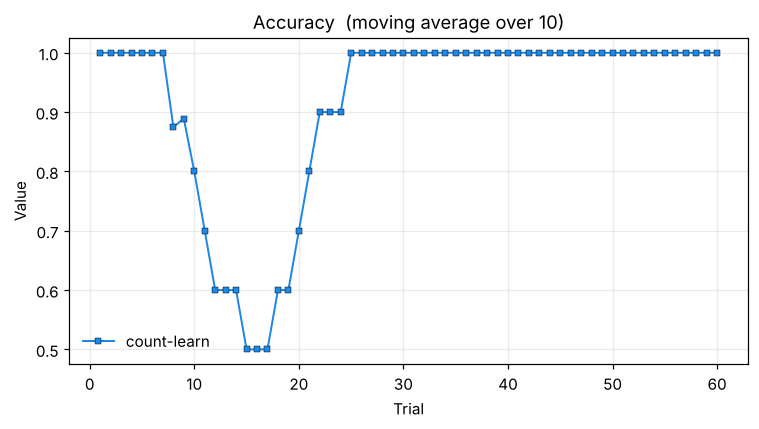

,source,target,Sji,updates
0,count-learn,final,2.855159,60
1,count-learn,iterate0,2.539840,118
2,count-learn,start-iteration,1.995750,60


In [4]:
cl = Session(seed=1)
cl.load("semantic.prims")
cl.load("count-learn.prims")
cl.run(60)
ax = cl.plot_results()
cl.associations("count-learn")

Even with only the semantic operators available, the model makes mistakes at first (the dip in accuracy; note that the first points of a moving average are not very informative): it still has to learn which operators lead to the reward within 10 seconds. The learned associations show that it has adopted the three operators it needs.

Now load a third model, `daydream`, whose operators also match in the counting task, and try again. The model again makes some mistakes at first, but quickly learns which operators to use: positive associations with the three semantic operators, negative ones with the daydream operators.

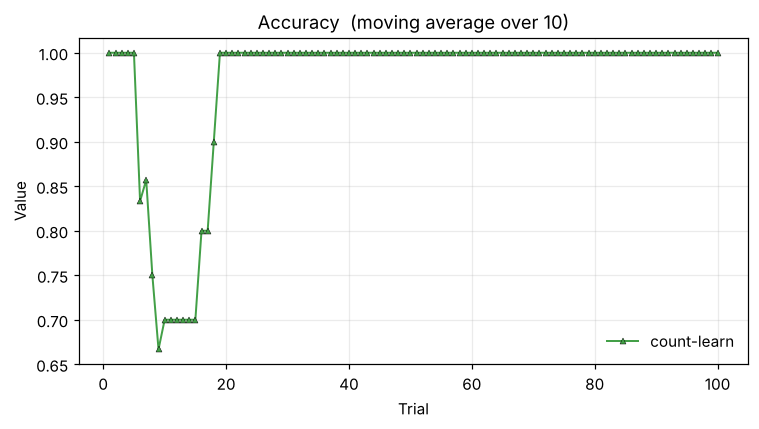

,source,target,Sji,updates
0,count-learn,final,2.953484,97
1,count-learn,iterate0,2.792299,175
2,count-learn,start-iteration,2.494728,98
3,count-learn,restart,-0.556913,4
4,count-learn,retrieve-episode,-0.569602,3
5,count-learn,associate,-0.935710,9


In [5]:
dd = Session(seed=1)
dd.load("semantic.prims")
dd.load("daydream.prims")
dd.load("count-learn.prims")
dd.run(100)
ax = dd.plot_results()
dd.associations("count-learn")

In the task graph, the learned associations between count-learn and operators are shown as red edges:

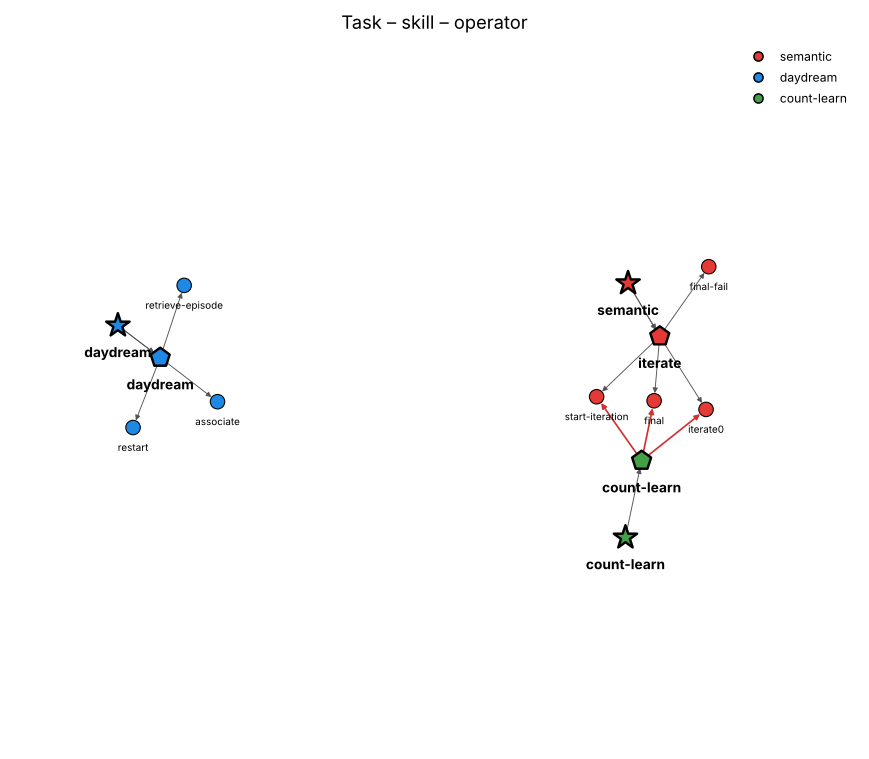

In [6]:
ax = dd.plot_graph(1, seed=2)

## Far transfer

Karbach and Kray have shown in an experiment that training on task switching transfers to several other control tasks, among which the Stroop task. You can load both models and check the overlap. The key to modeling transfer here is not so much that there is a large overlap between the two tasks (there isn't), but that this particular version of task switching trains a single skill that is useful for picking the better strategy for Stroop.

In this version of task switching, subjects have to keep track of the current task themselves: there is no external cue. The stimuli are pictures of fruit or vegetables, which can be either small or large. For the first two stimuli, subjects respond to fruit/vegetable, for the next two to large/small, the next two fruit/vegetable, and so on. This structure forces a strategy that **prepares** for the upcoming stimulus (other versions of task switching also allow a more reactive policy, so training on them may not always have the desired result).

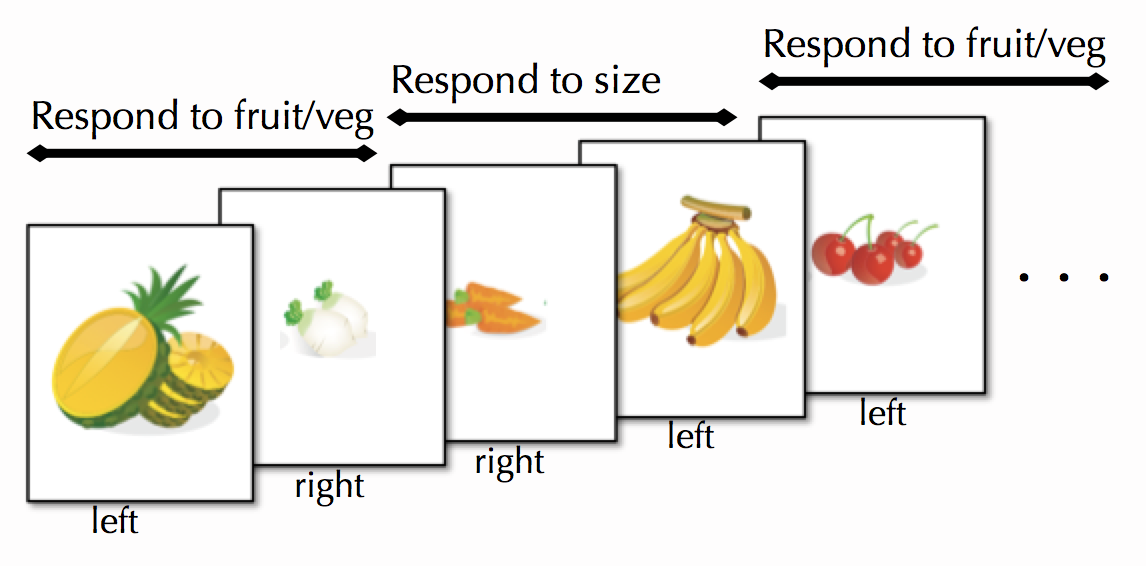

In [7]:
Image("figures/task-switching.png", width=600)

In the model this means that after a response has been made, it is not sufficient to wait for the next item: the model has to prepare what to do with that next item. But it should only prepare once.

Although this task should probably be broken down into a number of smaller skills, we restrict ourselves to two: a skill that carries out the choice-reaction task, and a skill that determines what the next property (food or size) to respond to is (`prepare-next`). The following operator, part of the main choice-reaction skill, switches to the prepare-next skill:

```
operator prepare-for-stimulus {
    V1 = fixation
    G2 = nil
==>
    *prepare -> G2
}
```

The variable `*prepare` is instantiated with the prepare-next skill in the script: `add-binding("prepare","prepare-next")`. The current task is represented in the `*property` variable, which is initially set to `food`.

While looking at the fixation cross, `prepare-for-stimulus` places the prepare-next skill in G2. This skill now has to decide what the task will be. To keep track, it keeps a counter in WM1. The first time the slot is empty, so it puts `one` in it, and then removes itself (meaning that `food` remains the `*property`):

```
operator set-first-task {
    V1 = fixation
    WM1 = nil
==>
    one -> WM1
    nil -> G2
    wait -> AC1
}
```

`wait` is a special action in PRIMs: the model waits until the next perceptual event happens. Although this is convenient, keep in mind that in reality our thinking never stops, and people probably fill any mental slack time with other thoughts.

After the task has been carried out (check the model to see whether you can figure out how it works), the model has to determine what to do next. It uses `prepare-for-stimulus` again to reinstate the prepare-next skill. The following operator of prepare-next starts determining the next task:

```
operator determine-next-task-retrieve-count {
    V1 = fixation
    RT1 = nil
    WM1 <> nil
==>
    count-fact -> RT1
    WM1 -> RT2
}
```

If the retrieved count fact gives *two* as the next number, the same task has to be done one more time; if it is *three*, the model changes to the other task. You can check that the appropriate operators are there to handle this:

In [8]:
show_model("task-switching.prims")

// Model of task switching from the Karbach and Kray experiment
// Adapted from the original PR model

define task task-switching {
    initial-skills: (choice-reaction)
    lf: 0.2
    egs: 0.05
    rt: -1.0
    input-activation: 0.0
    default-activation: 1.0
    alpha: 0.05
    goal-operator-learning: t
    operator-bll: t
    beta: 0.05
    reward: 80.0
    default-operator-assoc: 8.0
    default-inter-operator-assoc: 4.0
}

define skill choice-reaction {

    operator prepare-for-stimulus {
        V1 = fixation
        G2 = nil
        ==>
        *prepare -> G2
    }

    operator get-property {
        V1 = stimulus
        V2 = nil
        RT1 = nil
        ==>
        attend -> AC1
        *property -> AC2
    }

    operator get-mapping {
        V1 = stimulus
        V2 <> nil
        RT1 = nil
        ==>
        mapping -> RT1
        V2 -> RT2
    }

    operator press-key {
        RT1 = mapping
        ==>
        press -> AC1
        RT3 -> AC2
    }

    operator la

Whereas the task-switching model has no choice whether to prepare, the Stroop model does. It can just wait for the stimulus to appear, or it can prepare by getting ready to focus on the color only and ignore the word. If the model just attends the stimulus, both the word and the color are put in slots of the input buffer, but if the focus is on color only, only the color is represented. On a conflict trial with a regular attend action, spreading activation both increases and decreases the activation of the response, while on a consistent trial spreading activation only increases it. If the focus is on color only, this difference disappears.

Preparation in the Stroop model is done by the same operator as in task switching:

```
operator prepare-for-stimulus {
    V1 = fixation
    G2 = nil
==>
    *prepare -> G2
}
```

but now `*prepare` is instantiated with `focus-color`: `add-binding("prepare","focus-color")`. While watching the fixation cross, the model sets up a second skill that focuses on just the color when the stimulus appears. This skill has a single operator, `attend-just-color`, which carries out the attend-color action that puts the color of the ink in V2:

```
define skill focus-color {
    operator attend-just-color {
        V1 = stim
        V2 = nil
    ==>
        attend-color -> AC1
    }
}
```

The preparation strategy competes with the more default just-wait strategy:

```
operator just-wait(activation=1.5) {
    "Just wait for the stimulus"
    V1 = fixation
==>
    wait -> AC1
}

operator attend(activation=1.5) {
    V1 = stim
    V2 = nil
==>
    attend -> AC1
}
```

The `attend` action attends both the color of the ink (which appears in V2) and the identity of the word (in V3). If both attributes are attended, the identity of the word interferes with the color of the ink, but if only the color is attended, there is no interference.

The `(activation=1.5)` addition gives the default operators a higher base-level activation than the prepare operator, so they normally win the competition. However, `prepare-for-stimulus` also appears in the task-switching model. Training on task switching therefore increases the activation of that operator, making it more likely to be chosen after switching to Stroop.

Let us try this by hand. First the Stroop model on its own; each run of the script presents the four Stroop trials (two consistent, two conflict):

In [9]:
control = Session(seed=1)
control.load("stroop.prims")
control.run(20)
print(control.trace(1))

Presenting consistent with red-color and red-word 
276.56  Starting new trial
276.56  *** Retrieved operator just-wait with latency 0.000
277.56  *** Retrieved operator attend with latency 0.000
278.00  *** Retrieved operator retrieve-response with latency 0.000
278.39  *** Retrieved operator say-color with latency 0.000
278.97  End of trial
Presenting consistent with blue-color and blue-word 
278.97  *** Retrieved operator just-wait with latency 0.000
279.97  *** Retrieved operator attend with latency 0.000
280.41  *** Retrieved operator retrieve-response with latency 0.000
280.80  *** Retrieved operator say-color with latency 0.000
281.54  End of trial
Presenting conflict with red-color and blue-word 
281.54  *** Retrieved operator just-wait with latency 0.000
282.54  *** Retrieved operator attend with latency 0.000
282.98  *** Retrieved operator retrieve-response with latency 0.000
283.44  *** Retrieved operator say-color with latency 0.000
284.11  End of trial
Presenting conflict w

Now the Stroop model after 300 runs of the task-switching model (as in the batch file below):

In [10]:
transfer = Session(seed=1)
transfer.load("task-switching.prims")
transfer.run(300)
transfer.load("stroop.prims")
transfer.run(20)
print(transfer.trace(1))

Presenting consistent with red-color and red-word 
4330.40  Starting new trial
4330.40  *** Retrieved operator set-first-task with latency 0.000
4331.40  *** Retrieved operator attend-just-color with latency 0.000
4331.80  *** Retrieved operator retrieve-response with latency 0.000
4332.22  *** Retrieved operator say-color with latency 0.000
4332.82  End of trial
Presenting consistent with blue-color and blue-word 
4332.82  *** Retrieved operator set-first-task with latency 0.000
4333.82  *** Retrieved operator attend-just-color with latency 0.000
4334.22  *** Retrieved operator retrieve-response with latency 0.000
4334.62  *** Retrieved operator say-color with latency 0.000
4335.19  End of trial
Presenting conflict with red-color and blue-word 
4335.19  *** Retrieved operator set-first-task with latency 0.000
4336.19  *** Retrieved operator attend-just-color with latency 0.000
4336.59  *** Retrieved operator retrieve-response with latency 0.000
4337.00  *** Retrieved operator say-colo

After task switching, the model prepares for the stimulus (`prepare-for-stimulus`), and then uses `attend-just-color` instead of `attend`. How quickly this happens differs between runs of the model (with only 100 runs of task switching, many runs of the model never switch), which is one reason to run models in batch mode.

## Running models in batch mode

The notebook is fine to observe your model, and to see some qualitative evidence for learning and transfer, but to fit actual data you need to run the model hundreds of times, and average the results. For this, PRIMs uses **batch scripts** with the extension `.bprims`. They contain simple commands to run one or more models multiple times. `taskswitchstrooptransfer.bprims` is:

In [11]:
print(open("taskswitchstrooptransfer.bprims").read())

repeat 10
reset
run stroop stroop-control 100
reset
run task-switching task-switching 300
run stroop stroop-transfer 100


The first line always starts with `repeat` and a number: how often the rest of the script is run. `reset` puts the model back into its starting state. The `run` command has (at least) three arguments:

1. the name of the task. The name must match both the file name of the model (e.g., `stroop.prims`) and the name of the task in that file (the task must be called `stroop`, not `my-stroop`). pyprims looks for `stroop.py` first, and then `stroop.prims`, in the folder of the batch file;
2. a label that is put in the output. This is useful for processing the output: here we want to distinguish Stroop without prior experience (`stroop-control`) from Stroop after task switching (`stroop-transfer`);
3. the number of times to run the model.

Instead of `run`, you can use `run-time`. This works the same, except that the model runs for a certain amount of (simulated) time: give the time in seconds as the third argument.

With `run` and `run-time` you can also pass parameters to the model. Anything after the third argument is made available to the script: the script function `batch-parameters()` returns it as an array of strings. This is useful to vary parameters or conditions.

In the notebook, `s.batch(file)` runs a batch script and returns the output lines (add `out_path="name.txt"` to also write them to a file). From the command line, `python -m pyprims batch file.bprims -o output.txt` does the same. The output has one line per event, with these columns:

| column | meaning |
|---|---|
| `repeat` | the repetition (from 0) |
| `task`, `label` | task name and label from the `run` command |
| `trial` | trial number within the `run` command |
| `time` | time of the event, relative to the start of the trial |
| `event` | `action`, `trial-end`, or a `data-line` from the script |
| `p1`, `p2`, `p3` | the action (e.g., `say red`), or `success`/`fail` for a trial end |
| `in0` … `in4` | the fields set by `set-data-file-field` in the script |
| `firings` | the number of production firings |

`read_batch` turns the output into a pandas DataFrame. Running this batch takes about a minute:

In [12]:
out = Session().batch("taskswitchstrooptransfer.bprims", seed=1)
data = read_batch(out)
data.head(8)

,repeat,task,label,trial,time,event,p1,p2,p3,in0,in1,in2,in3,in4,firings
0,0,stroop,stroop-control,1,1.000000,action,wait,void,void,void,consistent,void,void,void,4
1,0,stroop,stroop-control,1,1.735310,action,attend,void,void,void,consistent,void,void,void,3
2,0,stroop,stroop-control,1,3.887846,action,say,red,void,void,consistent,void,void,void,8
3,0,stroop,stroop-control,1,3.887846,trial-end,success,void,void,void,consistent,void,void,void,0
4,0,stroop,stroop-control,1,1.000000,action,wait,void,void,void,consistent,void,void,void,2
5,0,stroop,stroop-control,1,1.735909,action,attend,void,void,void,consistent,void,void,void,3
6,0,stroop,stroop-control,1,3.923770,action,say,blue,void,void,consistent,void,void,void,8
7,0,stroop,stroop-control,1,3.923770,trial-end,success,void,void,void,consistent,void,void,void,0


The Stroop script sets data-file field 1 to the condition (`consistent` or `conflict`), so it is in column `in1`. The stimulus appears 1 second after the start of each trial, so the reaction time is the trial-end time minus 1.0. We take the second half of the Stroop trials (trial > 49) and average per label and condition:

In [13]:
stroop = data[(data.task == "stroop") & (data.event == "trial-end") & (data.trial > 49)]
stroop = stroop.assign(RT=stroop.time - 1.0)
table = stroop.groupby(["label", "in1"]).RT.mean().unstack().round(3)
table

in1,conflict,consistent
label,,
stroop-control,0.745,0.595
stroop-transfer,0.562,0.559


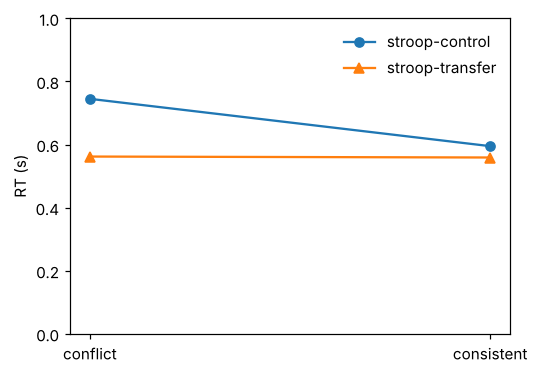

In [14]:
with figure(1, 1, figsize=(5, 3.5)) as ax:
    for label, marker in [("stroop-control", "o"), ("stroop-transfer", "^")]:
        ax.plot(["conflict", "consistent"], table.loc[label, ["conflict", "consistent"]], marker=marker, label=label)
    ax.set_ylim(0, 1); ax.set_ylabel("RT (s)"); ax.legend(frameon=False)

Without training, there is a Stroop effect: conflict trials are slower than consistent ones. After training on task switching the effect is (nearly) gone, because the model now prepares and attends only the color. Which actions did the model take?

In [15]:
data[(data.task == "stroop") & (data.event == "action")].groupby(["label", "p1"]).size().unstack(fill_value=0)

p1,attend,attend-color,say,wait
label,,,,
stroop-control,3997,0,4000,4000
stroop-transfer,2,3998,4000,4000


## Assignment: bottom-up learning

The learning we have looked at so far is about operators within a skill. But how are operators themselves learned? Operators are composed of PRIMs, so we need a learning story for how operators are learned from PRIMs.

You can find an initial experiment with this idea in the `bottom-up learning` subfolder. Look at `primitives.prims`. It contains a large collection of PRIMs encoded as small operators. For example, the `V1 -> RT1` PRIM is encoded as:

```
operator V1toRT1 {
    V1 <> nil
==>
    V1 -> RT1
    nil -> V1
}
```

In [16]:
show_model("bottom-up learning/primitives.prims")

define task primitives {
    initial-skills: (nogoal)
    default-activation: 1.0
    ol: t
    rt: -2.0
    lf: 0.2
    bll: 0.5
    default-operator-self-assoc: -2.0
    goal-operator-learning: t
    default-inter-operator-assoc: 0.0
    reward: 10.0
    beta: 0.1
}


define goal primitives {


operator V1toRT1 {
	V1 <> nil
==>
    V1 -> RT1
    nil -> V1
}

operator V1toRT2 {
	V1 <> nil
==>
    V1 -> RT2
    nil -> V1
}

operator V2toRT1 {
	V2 <> nil
==>
    V2 -> RT1
    nil -> V2
}

operator V2toRT2 {
	V2 <> nil
==>
    V2 -> RT2
    nil -> V2
}


operator RT2toAC1 {
	RT2 <> nil
==>
	action -> AC1
	RT2 -> AC2
}

operator RT1toAC1 {
	RT1 <> nil
==>
	action -> AC1
	RT1 -> AC2
}

operator RT2toRT1 {
	RT2 <> nil
==>
	RT2 -> RT1
}

operator RT3toRT2 {
	RT3 <> nil
==>
	RT3 -> RT2
}
	
operator V1toWM1 {
	V1 <> nil
	WM1 = nil
==>
   V1 -> WM1
   nil -> V1
}

operator V2toWM1 {
	V2 <> nil
	WM1 = nil
==>
   V2 -> WM1
   nil -> V2
}

operator WM1toRT1 {
	RT1 = nil
	WM1 <> nil
==>
    WM1 -> 

The other models in the folder only specify the task, but not the knowledge needed to carry it out. Your task is to experiment with these tasks, and look at what is learned. In addition to learning associations between operators and the skill, the models use an experimental form of **operator compilation** (`opc: t`). When the model reaches a reward, it tries to compile pairs of operators into new operators. For example, when learning the paired-associate task, the model might compile `V1toRT2` and `C1toRT1` into:

```
operator V1toRT2+C1toRT1 {
    V1 <> nil
    G1 <> nil
==>
    V1 -> RT2
    *fact-type -> RT1
    nil -> V1
}
```

A property of this new operator is that it retrieves exactly the right chunk, whereas both `V1toRT2` and `C1toRT1` can (and will) retrieve wrong chunks (the paired-associate model has several alternative facts in memory that would match).

To run one of the tasks, load `primitives.prims` first, and then the task. The models plot accuracy. Here is the paired-associate task:

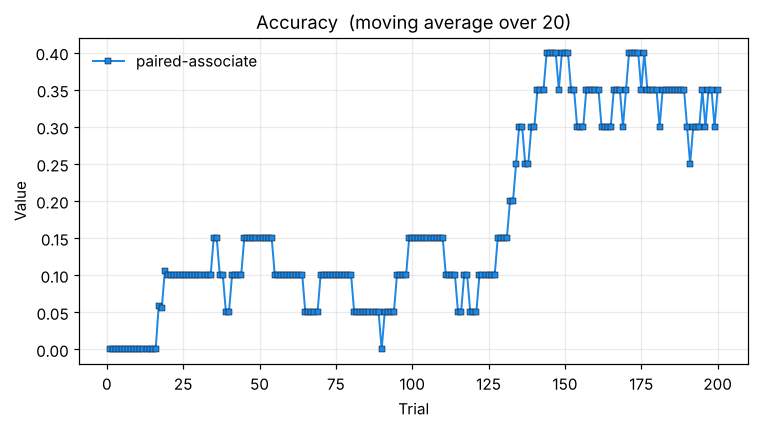

In [17]:
pa = Session(seed=1)
pa.load("bottom-up learning/primitives.prims")
pa.load("bottom-up learning/paired-associate.prims")
pa.run(200)
ax = pa.plot_results()

The operators that the model compiled, and the operators most strongly associated with the task:

In [18]:
print([c.name for c in pa.model.dm.chunks.values() if c.type == "operator" and "+" in c.name])
pa.associations("paired-associate").head(8)

['RT3toWM1+WM1toAC1', 'RT1equalC1+RT3toWM1+WM1toAC1', 'RT3toRT2+C1toRT1', 'RT1equalC1+RT2toRT1']


,source,target,Sji,updates
0,paired-associate,RT3toWM1+WM1toAC1,0.809897,64
1,paired-associate,RT1equalC1+RT3toWM1+WM1toAC1,-0.061889,19
2,paired-associate,C1toRT1,-0.067487,155
3,paired-associate,RT1equalC1+RT2toRT1,-0.157372,9
4,paired-associate,RT1equalC1,-0.311935,20
5,paired-associate,RT3toAC1,-0.648308,27
6,paired-associate,RT2toAC1,-1.384823,15
7,paired-associate,RT2toRT1,-1.461771,14


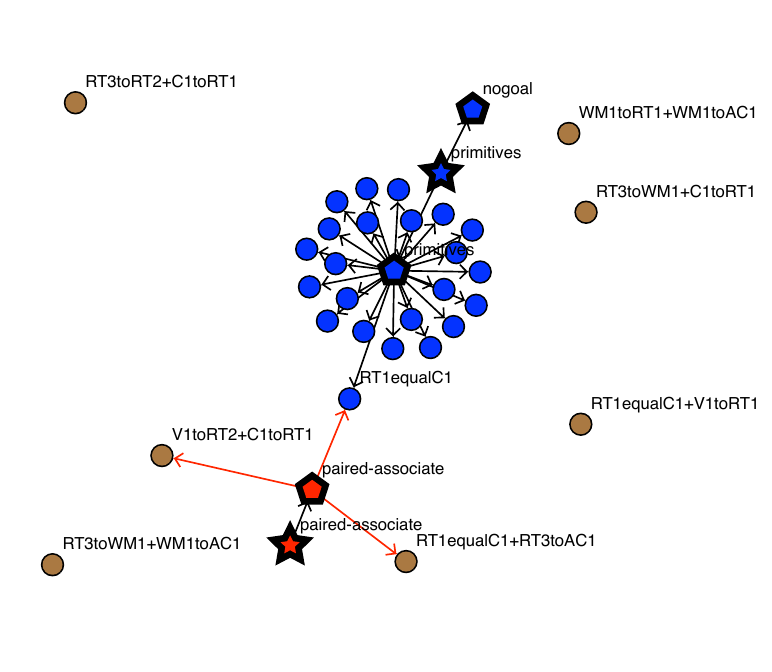

In [19]:
Image("figures/bottom-up-graph.png", width=450)

*Learning the paired-associate task: the model has learned several new operators (brown), two of which are useful for the task.*

**The assignment** is to try out the different tasks in the folder (`press-key`, `recall`, `paired-associate`, `category`, and their `-2` variants), and see how fast they learn, and what is learned. Try to identify the combinations of tasks between which there is transfer. Can you identify the operators that are instrumental in that transfer?

Tips:

* To test transfer from task A to task B, load primitives, A and B in one session (run A before loading B), and compare with a session that has only primitives and B. Use several seeds, or a batch file, because the learning is noisy.
* `session.associations(task)` shows what a task has learned to use (`learned=True` leaves out associations that were never updated); `plot_graph(1)` shows the same as red edges.
* The trace at level 5 shows the association updates (`Updating assoc between ...`).

**Next:** the `Reference` notebook lists all parameters, script functions and session functions.